# Solving Inverse Problem using weighted Connectome Spectrum Electromagnetic Tomography (wCSET)

wCSET solves the following optimization problem: 
$$\hat {\mathbf s}^* = \text{argmin}_{\mathbf{s}} \lVert \mathbf{LU}\hat{\mathbf s}-\mathbf{y} \rVert_2^2 + \lambda \lVert \mathbf D\hat{\mathbf s}\rVert_2^2$$
$$ \mathbf s^* = \mathbf U \hat{\mathbf s}$$

where
- $\mathbf{s}^* \in \mathbb{R}^n$ are the reconstructed dipole strengths
- $\hat{\mathbf{s}}^* \in \mathbb{R}^n$ is the reconstructed connectome spectrum.
- $\mathbf{y} \in \mathbb{R}^m$ are the EEG measurements.
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix.
- $\mathbf U \in \mathbb{R}^{n \times n}$ is the inverse graph Fourier transform
- $\lambda \in \mathbb{R}$ is the regularizer parameter.
- $\mathbf D \in \mathbb{R}^{n\times n}$ is a diagonal matrix weighting the harmonics.

The particularity of wCSET is that it weights the harmonic according to the gap frequencies. The idea comes from the fact that most reconstructions (CSET and sLORETA) rebuild the low frequency harmonics (integrative) and very high frequency harmonics (segregative) but not as much the center harmonics (degenerative). These frequencies are each defined by there gap frequency (low gap for degenerative and high gap for integrative/segregative). So the plan here is to enforce this imbalance to see how it affects the source reconstruction.

## 📦 Imports

In [1]:
import mindmap as mm
import pygsp
import numpy as np 

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG
- `fwd`: Forward operator
- `cst`: Connectome spectrum transform
- `gt`: Ground Truth (optional)
- `resec`: Resection area 

In [2]:
################# Parameters ####################
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
samp    = 1
#################################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "fwd", "sc", "eeg", "gt", "resec", sample=samp)

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- fwd
- eeg
- sc
- gt
Missing objects:
- resec


# EEG 
🌟 **Visualize EEG topographic maps at 50% rising phase and peak phase**

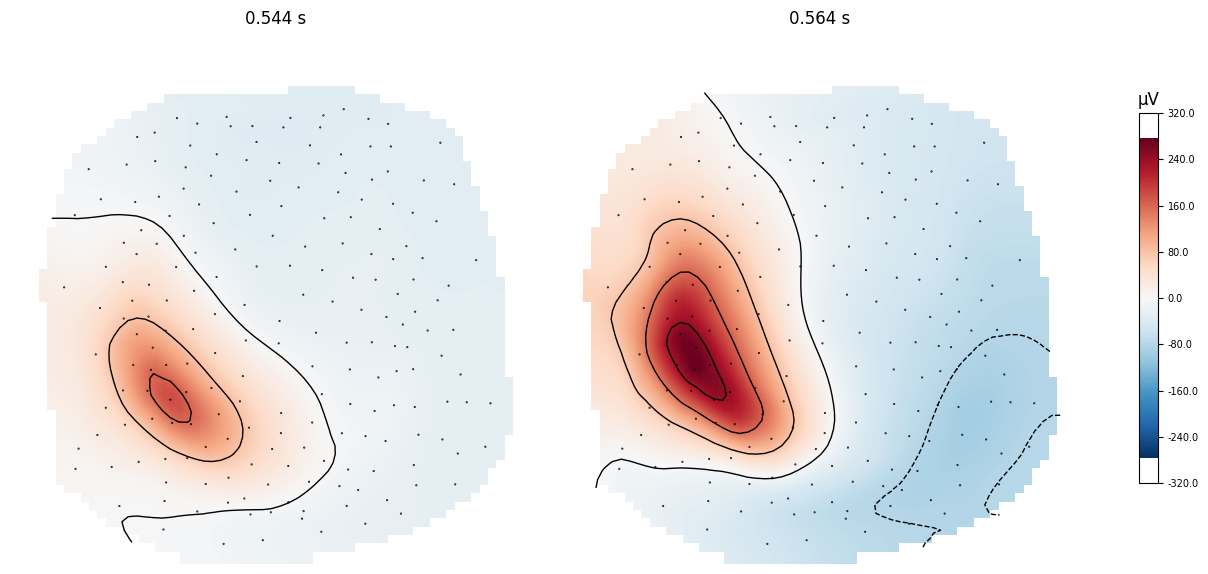

In [3]:
hrp_time  = mm.utils.eeg_rising_phase(data["eeg"], ratio=0.5)    # half rising phase
peak_time = mm.utils.eeg_rising_phase(data["eeg"], ratio=1)      # peak phase

times = [hrp_time, peak_time]
_ = data["eeg"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

🎚️ <font color=violet>**Time window**</font>:
- `win_size`: time window around EEG peak in [s]

Number of samples: 76


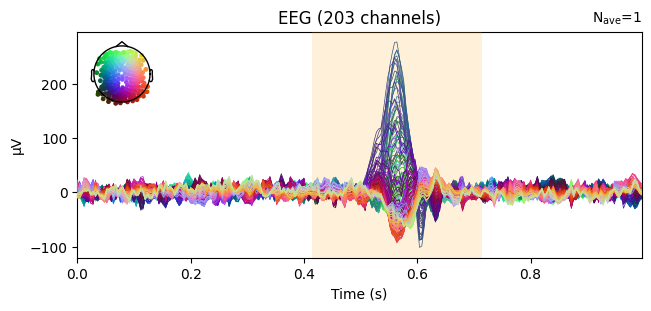

In [4]:
########### Parameters ###############
win_size = 0.3
######################################

window    = data["eeg"].copy()
highlight = None

if win_size is not None:
    dt = win_size/2 
    window = window.crop(peak_time-dt, peak_time+dt)

    highlight = [peak_time-dt, peak_time+dt]

print(f"Number of samples: {len(window.times)}")
_ = data["eeg"].plot(highlight=highlight)

## wCSET solution

#### ⚙️ <font color=green>**Instanciate weights**</font>

The weights are extracted from the eigenvalues of structural connectome. So we will recompute the eigenvectors (graph Fourier transform) and eigenvalues here.

🎚️ <font color=pink>**Weights**</font>:
- `relax`: Relaxation parameter for computing weights

In [ ]:
################## Parameters ###################
# weights
relax = 0.2
#################################################

pos = mm.utils.get_src_position(data["fwd"]["src"])
G = pygsp.graphs.Graph(data["sc"], lap_type="normalized", coords=pos)
G.compute_fourier_basis()

cst     = G.U.T
eigvals = G.e

weights = mm.utils.harmonic_weights(eigvals, relaxation=relax)
mm.viz.plot_spectrum(weights)

2025-06-04 15:53:14,357:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.


#### ⚙️ <font color=green>**Compute wCSET solution**</font>

🎚️ <font color=pink>**Regularizer**</font>:
- `lam`: Regularizer parameter

In [ ]:
############## Parameters #############
lam = 0.1
#######################################

stc = mm.wcset(
    eeg     = window,
    fwd     = data["fwd"],
    cst     = cst,
    weights = weights,
    lam     = lam,
)

print("\033[92mReconstruction finished\033[0m")

Reconstruction finished


🌟 **Visualize solution** <br>

In [24]:
try:
    overlay = data["resec"]
except:
    overlay = None 

try: 
    ground_truth = data["gt"]
    ground_truth = ground_truth.crop(stc.times[0], stc.times[-1])
    signals = [stc, ground_truth]
    titles  = ["wCSET", "Ground Truth"]
except:
    signals = [stc] 
    titles  = "wCSET"

signals = [mm.utils.squared_stc(s) for s in signals]
signals = [mm.utils.standardize_stc(s, timepoint_wise=True) for s in signals]

print(f"Half rising phase time: {hrp_time}")
print(f"Peak time: {peak_time}")

mm.viz.plot_brain(data["fwd"]["src"], signals, title=titles, overlay=overlay, overlay_size=1, overlay_opacity=1, smooth_shading=True).show()

Half rising phase time: 0.544
Peak time: 0.564


Widget(value='<iframe src="http://localhost:35027/index.html?ui=P_0x72b6a12b6dd0_3&reconnect=auto" class="pyvi…

🌟 **Visualize spectrum** <br>

In [26]:
spec = cst@data["gt"].data
mm.viz.plot_spectrum(spec, stc.times)